In [1]:
print("Hello, World!")

Hello, World!


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from math import log, tanh
import numpy as np

In [3]:
Wage = pd.read_csv("ISLR/data/Wage.csv", index_col=0)
Wage.head()

,year,age,maritl,race,education,region,jobclass,health,health_ins,logwage,wage
231655,2006,18,1. Never Married,1. White,1. < HS Grad,2. Middle Atlantic,1. Industrial,1. <=Good,2. No,4.318063,75.043154
86582,2004,24,1. Never Married,1. White,4. College Grad,2. Middle Atlantic,2. Information,2. >=Very Good,2. No,4.255273,70.476020
161300,2003,45,2. Married,1. White,3. Some College,2. Middle Atlantic,1. Industrial,1. <=Good,1. Yes,4.875061,130.982177
155159,2003,43,2. Married,3. Asian,4. College Grad,2. Middle Atlantic,2. Information,2. >=Very Good,1. Yes,5.041393,154.685293
11443,2005,50,4. Divorced,1. White,2. HS Grad,2. Middle Atlantic,2. Information,1. <=Good,1. Yes,4.318063,75.043154


In [4]:
print("Shape of Wage: ", Wage.shape[1])
print("Features of Wage: ", list(Wage.columns))

Shape of Wage:  11
Features of Wage:  ['year', 'age', 'maritl', 'race', 'education', 'region', 'jobclass', 'health', 'health_ins', 'logwage', 'wage']


In [5]:
Wage = Wage.drop(columns=["logwage"])
print("Shape of Wage, after dropping logwage: ", Wage.shape[1])
print("Features of Wage, after dropping logwage: ", list(Wage.columns))

Shape of Wage, after dropping logwage:  10
Features of Wage, after dropping logwage:  ['year', 'age', 'maritl', 'race', 'education', 'region', 'jobclass', 'health', 'health_ins', 'wage']


In [6]:
Wage.shape[0]

3000

In [7]:
Wage

,year,age,maritl,race,education,region,jobclass,health,health_ins,wage
231655,2006,18,1. Never Married,1. White,1. < HS Grad,2. Middle Atlantic,1. Industrial,1. <=Good,2. No,75.043154
86582,2004,24,1. Never Married,1. White,4. College Grad,2. Middle Atlantic,2. Information,2. >=Very Good,2. No,70.476020
161300,2003,45,2. Married,1. White,3. Some College,2. Middle Atlantic,1. Industrial,1. <=Good,1. Yes,130.982177
155159,2003,43,2. Married,3. Asian,4. College Grad,2. Middle Atlantic,2. Information,2. >=Very Good,1. Yes,154.685293
11443,2005,50,4. Divorced,1. White,2. HS Grad,2. Middle Atlantic,2. Information,1. <=Good,1. Yes,75.043154
...,...,...,...,...,...,...,...,...,...,...
376816,2008,44,2. Married,1. White,3. Some College,2. Middle Atlantic,1. Industrial,2. >=Very Good,1. Yes,154.685293
302281,2007,30,2. Married,1. White,2. HS Grad,2. Middle Atlantic,1. Industrial,2. >=Very Good,2. No,99.689464
10033,2005,27,2. Married,2. Black,1. < HS Grad,2. Middle Atlantic,1. Industrial,1. <=Good,2. No,66.229408
14375,2005,27,1. Never Married,1. White,3. Some College,2. Middle Atlantic,1. Industrial,2. >=Very Good,1. Yes,87.981033


In [8]:
Wage.describe(include='all')

,year,age,maritl,race,education,region,jobclass,health,health_ins,wage
count,3000.000000,3000.000000,3000,3000,3000,3000,3000,3000,3000,3000.000000
unique,NaN,NaN,5,4,5,1,2,2,2,NaN
top,NaN,NaN,2. Married,1. White,2. HS Grad,2. Middle Atlantic,1. Industrial,2. >=Very Good,1. Yes,NaN
freq,NaN,NaN,2074,2480,971,3000,1544,2142,2083,NaN
mean,2005.791000,42.414667,NaN,NaN,NaN,NaN,NaN,NaN,NaN,111.703608
std,2.026167,11.542406,NaN,NaN,NaN,NaN,NaN,NaN,NaN,41.728595
min,2003.000000,18.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20.085537
25%,2004.000000,33.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,85.383940
50%,2006.000000,42.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,104.921507
75%,2008.000000,51.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,128.680488


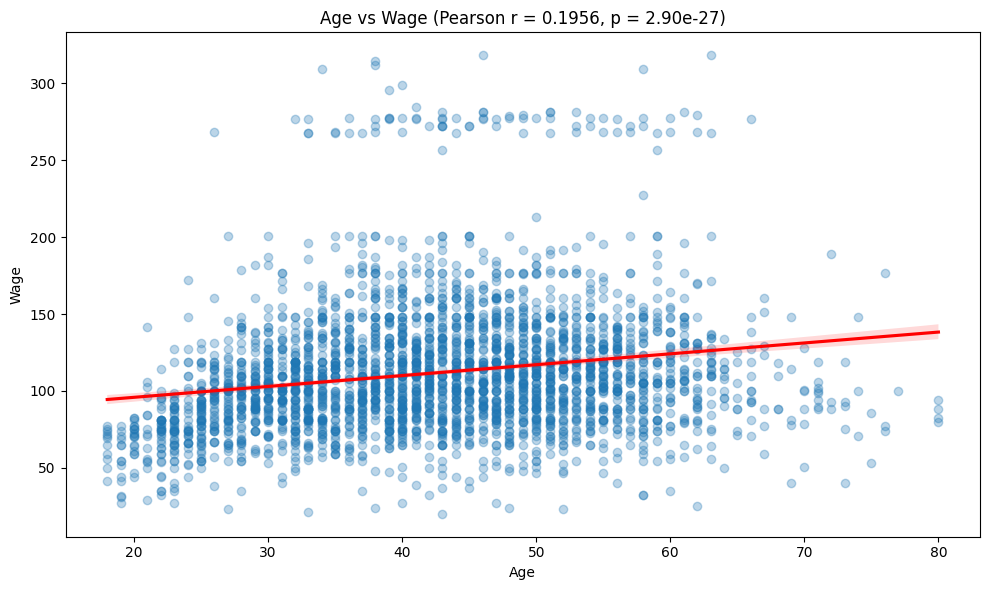

In [9]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.regplot(x='age', y='wage', data=Wage, scatter_kws={'alpha':0.3}, line_kws={'color':'red'}, ax=ax)
r, p = stats.pearsonr(Wage['age'], Wage['wage'])
ax.set_title(f'Age vs Wage (Pearson r = {r:.4f}, p = {p:.2e})')
ax.set_xlabel('Age')
ax.set_ylabel('Wage')
plt.tight_layout()
plt.show()

In [10]:
sample_size = min(5000, len(Wage))
age_sample = Wage['age'].sample(sample_size, random_state=42)
wage_sample = Wage['wage'].sample(sample_size, random_state=42)

stat_age, p_age = stats.shapiro(age_sample)
stat_wage, p_wage = stats.shapiro(wage_sample)

print("Shapiro-Wilk Normality Test for Age:")
print(f"  W = {stat_age:.4f}, p-value = {p_age}")
print(f"  {'Not normal' if p_age < 0.05 else 'Normal'} (at α=0.05)")

print("\nShapiro-Wilk Normality Test for Wage:")
print(f"  W = {stat_wage:.4f}, p-value = {p_wage}")
print(f"  {'Not normal' if p_wage < 0.05 else 'Normal'} (at α=0.05)")

Shapiro-Wilk Normality Test for Age:
  W = 0.9911, p-value = 9.416337654404108e-13
  Not normal (at α=0.05)

Shapiro-Wilk Normality Test for Wage:
  W = 0.8796, p-value = 2.463070103678234e-43
  Not normal (at α=0.05)


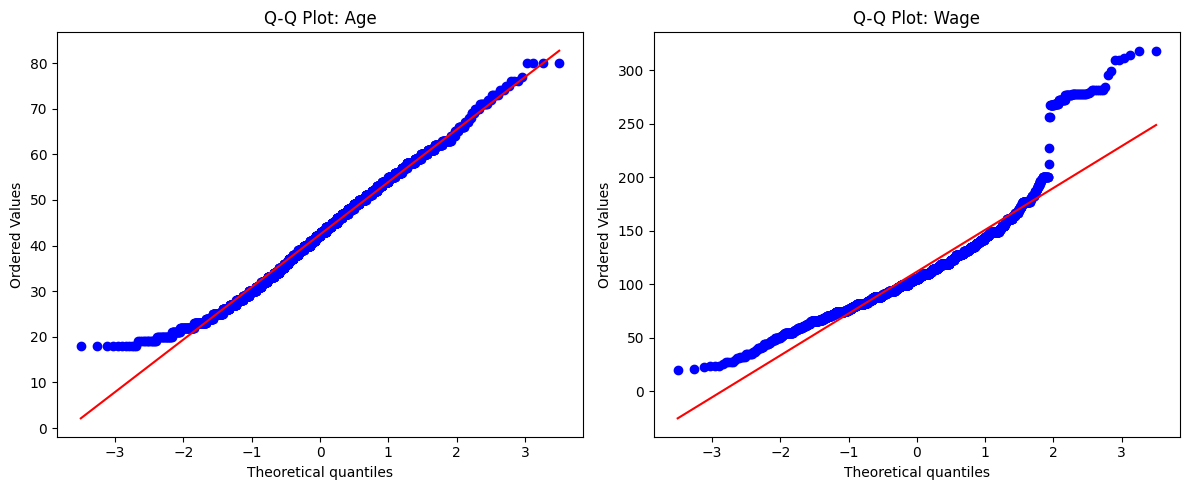

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

stats.probplot(Wage['age'], dist="norm", plot=axes[0])
axes[0].set_title('Q-Q Plot: Age')

stats.probplot(Wage['wage'], dist="norm", plot=axes[1])
axes[1].set_title('Q-Q Plot: Wage')

plt.tight_layout()
plt.show()

In [12]:
r, p = stats.pearsonr(Wage['age'], Wage['wage'])
n = len(Wage)

se = 1 / ((n - 3) ** 0.5)
z = 0.5 * np.log((1 + r) / (1 - r))
z_lower = z - 1.96 * se
z_upper = z + 1.96 * se
r_lower = np.tanh(z_lower)
r_upper = np.tanh(z_upper)

print("Pearson's product-moment correlation")
print("=" * 45)
print(f"data: Wage['age'] and Wage['wage']")
print(f"t = {r * ((n-2)/(1-r**2))**0.5:.3f}, df = {n-2}, p-value = {p:.2e}")
print(f"alternative hypothesis: true correlation is not equal to 0")
print(f"95 percent confidence interval: [{r_lower:.7f}, {r_upper:.7f}]")
print(f"sample estimate (cor): {r:.7f}")

Pearson's product-moment correlation
data: Wage['age'] and Wage['wage']
t = 10.923, df = 2998, p-value = 2.90e-27
alternative hypothesis: true correlation is not equal to 0
95 percent confidence interval: [0.1609771, 0.2298154]
sample estimate (cor): 0.1956372


In [13]:
print("Unique values for 'education':")
print(Wage['education'].unique())

Unique values for 'education':
<StringArray>
[      '1. < HS Grad',    '4. College Grad',    '3. Some College',
         '2. HS Grad', '5. Advanced Degree']
Length: 5, dtype: str


/var/folders/2z/bd17dm2577gbxxvhvfvsj2lw0000gn/T/ipykernel_10893/3277231505.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='education', y='wage', data=Wage, palette='Set2', ax=ax)


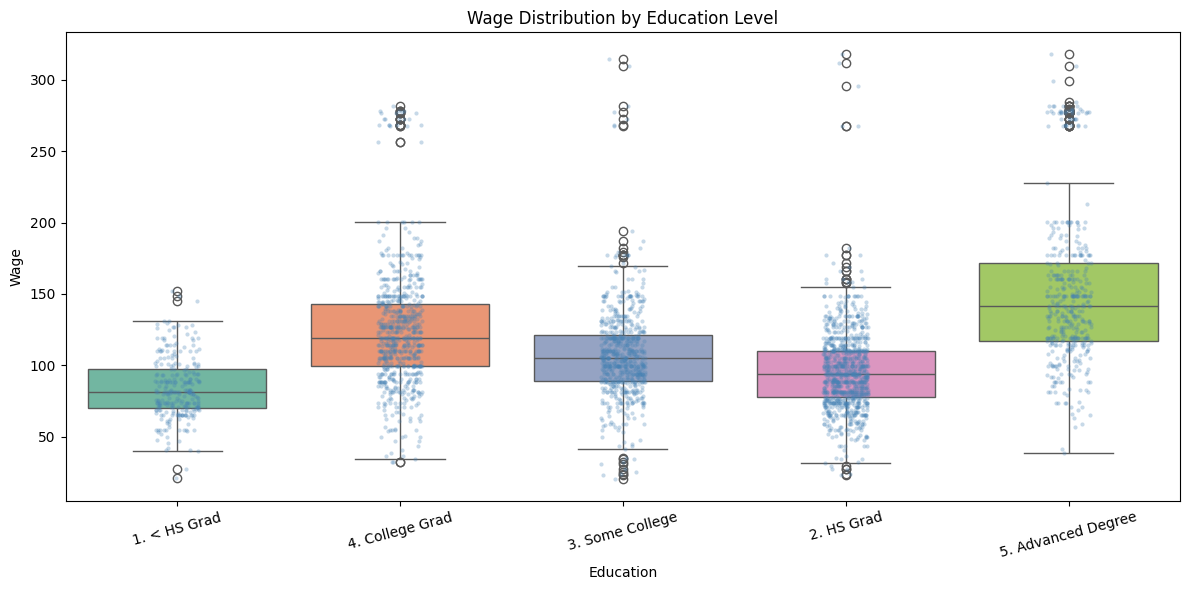

In [14]:

fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(x='education', y='wage', data=Wage, palette='Set2', ax=ax)
sns.stripplot(x='education', y='wage', data=Wage, color='steelblue', alpha=0.3, size=3, ax=ax)
ax.set_xlabel('Education')
ax.set_ylabel('Wage')
ax.set_title('Wage Distribution by Education Level')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [15]:
model = ols('wage ~ C(education)', data=Wage).fit()
anova_table = sm.stats.anova_lm(model, typ=2)
print("One-way ANOVA: Wage ~ Education")
print("=" * 60)
print(anova_table)
print("\nSignificance codes: 0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1")

One-way ANOVA: Wage ~ Education
                    sum_sq      df           F         PR(>F)
C(education)  1.226364e+06     4.0  229.805921  2.915932e-172
Residual      3.995721e+06  2995.0         NaN            NaN

Significance codes: 0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1


## Interpretation of Results
### Correlation by Age and Wage

The Pearson correlation coefficient r=0.1956 indicates a weak positive linear relationship between age and wage in the dataset

The t statistic of 10.923 with 2998 degrees of freedom and an extremely small p value (~0) confirms that this correlation is statistically significant meaning we can reject the null hypothesis that there is no relationship between age and wage

The 95 percent confidence interval ranging from 0.1610 to 0.2298 tellls us that we can be 95 percent confident the true population correlation falls within this range, however the practical significance is limited because age explains only about 3.8 percent of the variance in wages calculated as r squared which equals 0.038


### Normality Tests

The Shapiro Wilk test results reveal that neither variable follows a normal distribution

- Age has W statistic of 0.9911 and samll p value (~0)
- Wage has W statistic of 0.8796 and p value (~0)

Both p values are far below the 0.05 significance level leading us to reject the null hypothesis of normality for both variables

The Q-Q plots confirms these findings by showing data points deviating from the theoretical normal line especially in each ending of the distributions

### Education on Wage affect

ANOVA test examining wage diferences across 5 education levels produced remarkable results

The F statistic of 229.81 is large indicating substantial diferences in mean wages among education groupes

Small p value (~0) means there is virtually no probability that these wage diferences occurred by chance alone

It all means that education level has an extremely powerful and statistically significant effect on wages making it the most important factor in this analysis

### Overall

Education emerges as the dominant factor determining wages in this dataset while age plays a secondary role with limited practical impact

These findings suggest that investing in education is likely to have a much greater impact on earning potential than simply gaining work experience through age